# Bloc A — Exploratory Data Analysis

## Introduction and Objective

This notebook presents the Exploratory Data Analysis (EDA) for Bloc A of the Financial Time Series project. The objective is to characterise the statistical properties of three financial assets — **Oil (WTI crude oil futures, Yahoo Finance `CL=F`)**, **Gold (COMEX gold futures, Yahoo Finance `GC=F`)**, and the **S&P 500 index (`^GSPC`)** — using their daily **closing** prices. The full cleaned sample spans **2021-10-01 to 2026-10-01** (1,255 synchronized trading days in `prices_clean.csv`); all inferential EDA below uses the **training split only**.

The EDA covers the following topics:

1. Data loading and validation
2. Original price evolution (un-normalized price levels)
3. Normalized price comparison
4. Log returns over time
5. Return distributions
6. Descriptive statistics (mean, standard deviation, skewness, excess kurtosis)
7. Outlier analysis of training returns
8. Correlation analysis (Pearson correlation matrix and heatmap)
9. 20-day rolling volatility
10. Seasonal decomposition (STL) of training prices
11. Stationarity analysis (ADF and KPSS tests)
12. ACF and PACF analysis of training returns
13. Ljung–Box test on training returns
14. ACF of squared and absolute returns (volatility clustering)
15. ARCH-LM test for conditional heteroskedasticity
16. Key observations and conclusions

All analyses that rely on in-sample inference use the **training split only** (2021-10-01 to 2026-04-01, 1,129 price observations / 1,128 return observations) to prevent any leakage from the hold-out test period (2026-04-02 to 2026-10-01, 126 observations).

---


## 1. Data Loading and Validation

The training price and return datasets are loaded from the processed data directory. Both files were produced by `src/split_data.py`, which performs a strict chronological 90/10 split on `data/processed/prices_clean.csv`. Raw downloads are defined in `src/download_data.py` (Yahoo Finance tickers `CL=F`, `GC=F`, `^GSPC`).

The cell below confirms dataset shape, displays the first rows, and checks duplicate dates, chronological ordering, missing values, and date alignment across Oil, Gold, and S&P 500.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate the project root and processed data.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Load the training datasets only.
prices = pd.read_csv(
    DATA_DIR / "train_prices.csv",
    index_col=0,
    parse_dates=True,
)

returns = pd.read_csv(
    DATA_DIR / "train_returns.csv",
    index_col=0,
    parse_dates=True,
)

# Basic reproducibility and plotting settings.
plt.rcParams["figure.figsize"] = (12, 6)
sns.set_theme(style="whitegrid")

print("Training prices:", prices.shape)
print("Training returns:", returns.shape)
print("Training price period:", prices.index.min(), "to", prices.index.max())
print("Training return period:", returns.index.min(), "to", returns.index.max())

display(prices.head())
display(returns.head())

print("\n--- Missing values ---")
print("Training prices:\n", prices.isna().sum())
print("Training returns:\n", returns.isna().sum())

print("\n--- Duplicate dates (index) ---")
print("Prices duplicate dates:", int(prices.index.duplicated().sum()))
print("Returns duplicate dates:", int(returns.index.duplicated().sum()))

print("\n--- Chronological index ordering ---")
print("Prices strictly increasing:", prices.index.is_monotonic_increasing)
print("Returns strictly increasing:", returns.index.is_monotonic_increasing)

print("\n--- Cross-asset date alignment (training) ---")
common_dates = prices.index.intersection(returns.index)
print("Price/return common dates:", len(common_dates), "(returns omit first price day)")
print("Returns dates subset of price dates:", returns.index.isin(prices.index).all())
print("Price rows with any missing asset:", int(prices.isna().any(axis=1).sum()))
print("Return rows with any missing asset:", int(returns.isna().any(axis=1).sum()))


Training prices: (1129, 3)
Training returns: (1128, 3)
Training price period: 2021-10-01 00:00:00 to 2026-04-01 00:00:00
Training return period: 2021-10-04 00:00:00 to 2026-04-01 00:00:00


,Oil,Gold,SP500
Date,,,
2021-10-01,75.879997,1758.400024,4357.040039
2021-10-04,77.620003,1767.599976,4300.459961
2021-10-05,78.930000,1760.900024,4345.720215
2021-10-06,77.430000,1761.800049,4363.549805
2021-10-07,78.300003,1759.199951,4399.759766


,Oil,Gold,SP500
Date,,,
2021-10-04,0.022672,0.005218,-0.013071
2021-10-05,0.016736,-0.003798,0.010470
2021-10-06,-0.019187,0.000511,0.004094
2021-10-07,0.011173,-0.001477,0.008264
2021-10-08,0.013321,-0.001024,-0.001916



--- Missing values ---
Training prices:
 Oil      0
Gold     0
SP500    0
dtype: int64
Training returns:
 Oil      0
Gold     0
SP500    0
dtype: int64

--- Duplicate dates (index) ---
Prices duplicate dates: 0
Returns duplicate dates: 0

--- Chronological index ordering ---
Prices strictly increasing: True
Returns strictly increasing: True

--- Cross-asset date alignment (training) ---
Price/return common dates: 1128 (returns omit first price day)
Returns dates subset of price dates: True
Price rows with any missing asset: 0
Return rows with any missing asset: 0


### Asset identifiers (data provenance)

| Column | Yahoo Finance ticker | Instrument (as downloaded) |
|--------|---------------------|----------------------------|
| Oil | `CL=F` | WTI crude oil futures (daily close) |
| Gold | `GC=F` | COMEX gold futures (daily close), **not** a verified spot bullion series |
| SP500 | `^GSPC` | S&P 500 index (daily close) |

Gold is therefore described as **gold futures** throughout this notebook unless a separate spot source is added later.


In [2]:
# Chronological 90/10 split is fixed in src/split_data.py — training files only here.
assert prices.index.max() < pd.Timestamp("2026-04-02"), "Expected training prices to end before test period"
print("Hold-out test period (not used in this notebook): 2026-04-02 to 2026-10-01")


Hold-out test period (not used in this notebook): 2026-04-02 to 2026-10-01


## 2. Original Price Evolution

The plot below displays the historical daily closing prices in their original, un-normalized units (USD per barrel for WTI oil futures, USD per troy ounce for COMEX gold futures, and index points for the S&P 500) over the training period.

Separate subplots are used to maintain visual readability across differing price scales.


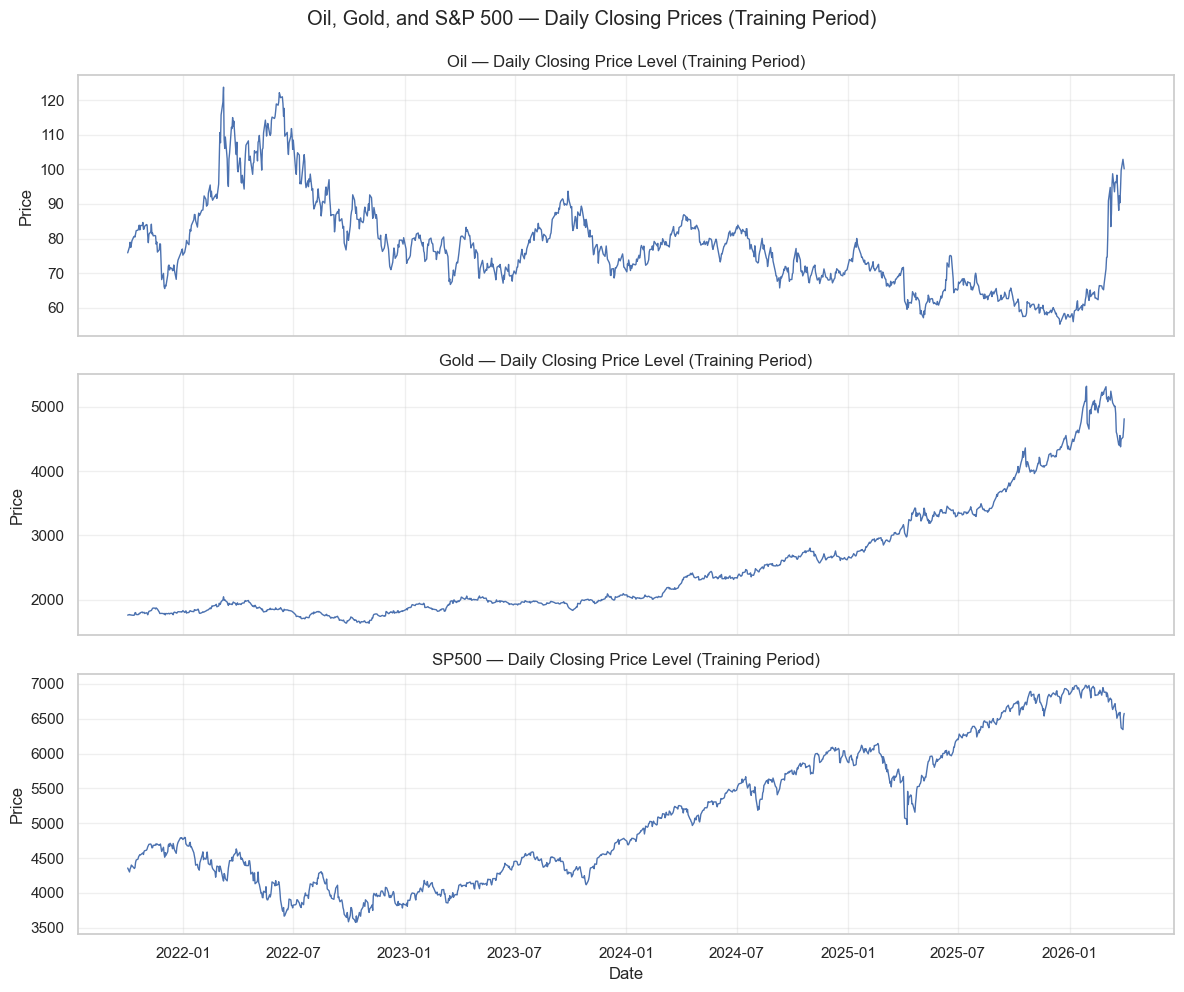

In [3]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 10), sharex=True)

for ax, asset in zip(axes, prices.columns):
    ax.plot(prices.index, prices[asset], linewidth=1.0)
    ax.set_title(f"{asset} — Daily Closing Price Level (Training Period)")
    ax.set_ylabel("Price")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")
plt.suptitle("Oil, Gold, and S&P 500 — Daily Closing Prices (Training Period)", y=0.99)
plt.tight_layout()
plt.show()

## 3. Normalized Prices

To compare the three assets on a common scale, each price series is indexed to **100 at the first training observation (2021-10-01)**. A value above 100 indicates cumulative appreciation relative to the base date; a value below 100 indicates cumulative depreciation.

The normalization is computed in-memory from the training prices loaded in Section 1 using the formula: `normalized = price / price[first date] * 100`.

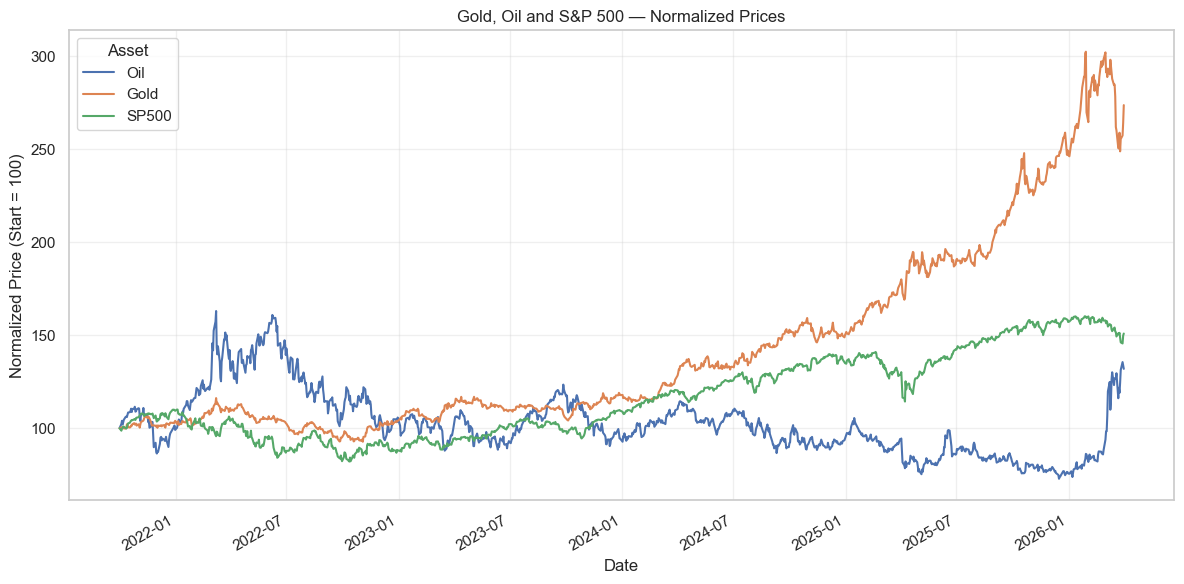

In [4]:

# Normalize each asset to 100 at the first training observation.
normalized_prices = prices.div(prices.iloc[0]).mul(100)

fig, ax = plt.subplots(figsize=(12, 6))

normalized_prices.plot(ax=ax, linewidth=1.5)

ax.set_title("Gold, Oil and S&P 500 — Normalized Prices")
ax.set_xlabel("Date")
ax.set_ylabel("Normalized Price (Start = 100)")
ax.legend(title="Asset")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Log Returns Over Time

Daily logarithmic returns are defined as $r_t = \ln(P_t / P_{t-1})$. Log returns are preferred over simple returns for time-series modelling because they are additive across time and approximately normally distributed for small changes.

The chart below shows the full training return series for each asset. Periods of elevated volatility — visible as clusters of large positive and negative returns — are consistent with the volatility clustering that motivates GARCH-type models.

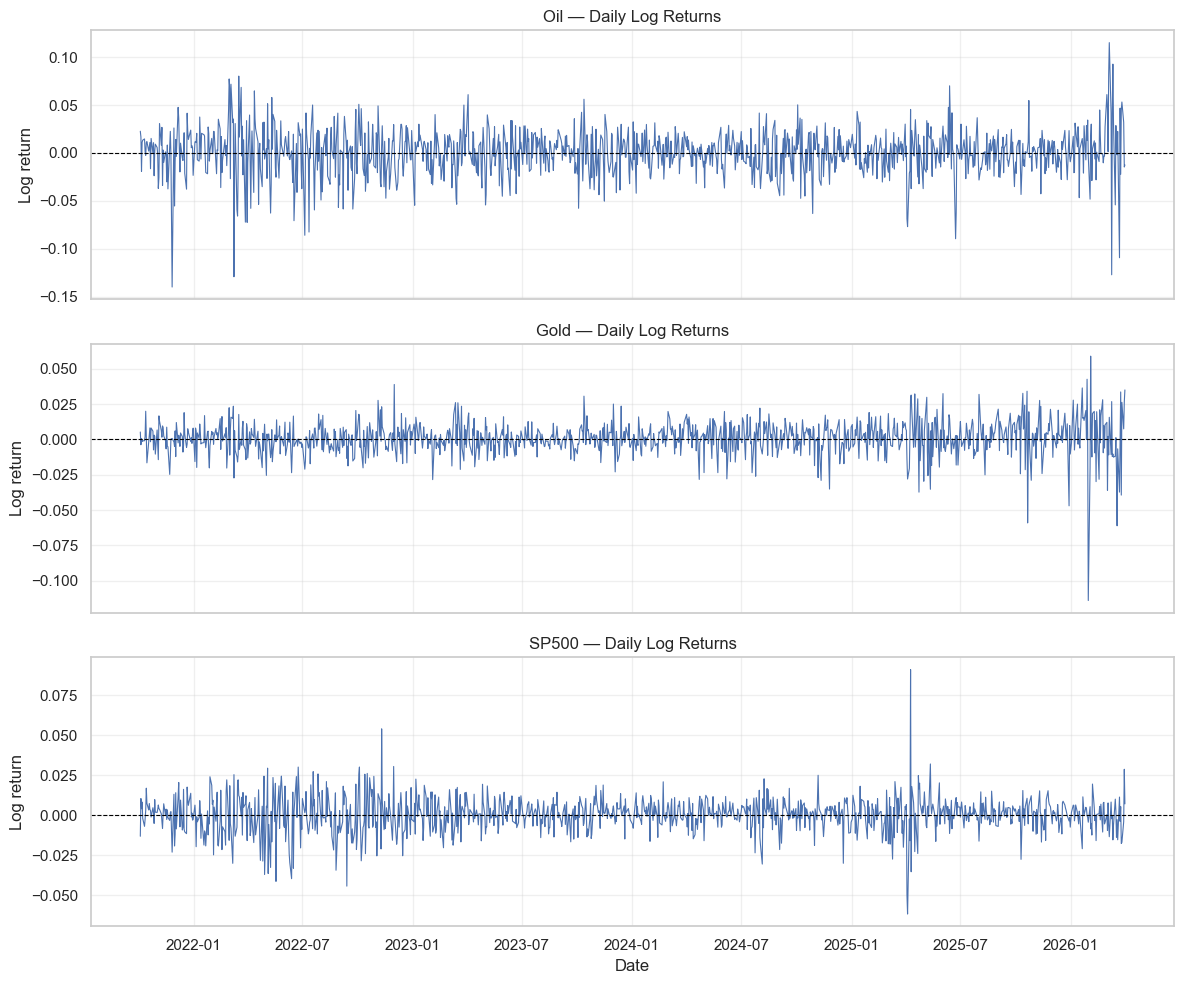

In [5]:

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 10),
    sharex=True,
)

for ax, asset in zip(axes, returns.columns):
    ax.plot(returns.index, returns[asset], linewidth=0.8)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"{asset} — Daily Log Returns")
    ax.set_ylabel("Log return")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

## 5. Return Distributions

The histograms below show the empirical distribution of daily log returns for Oil, Gold, and the S&P 500 over the training period.

Financial return distributions typically exhibit **fat tails (leptokurtosis)** and slight asymmetry compared to a theoretical Gaussian (normal) distribution.

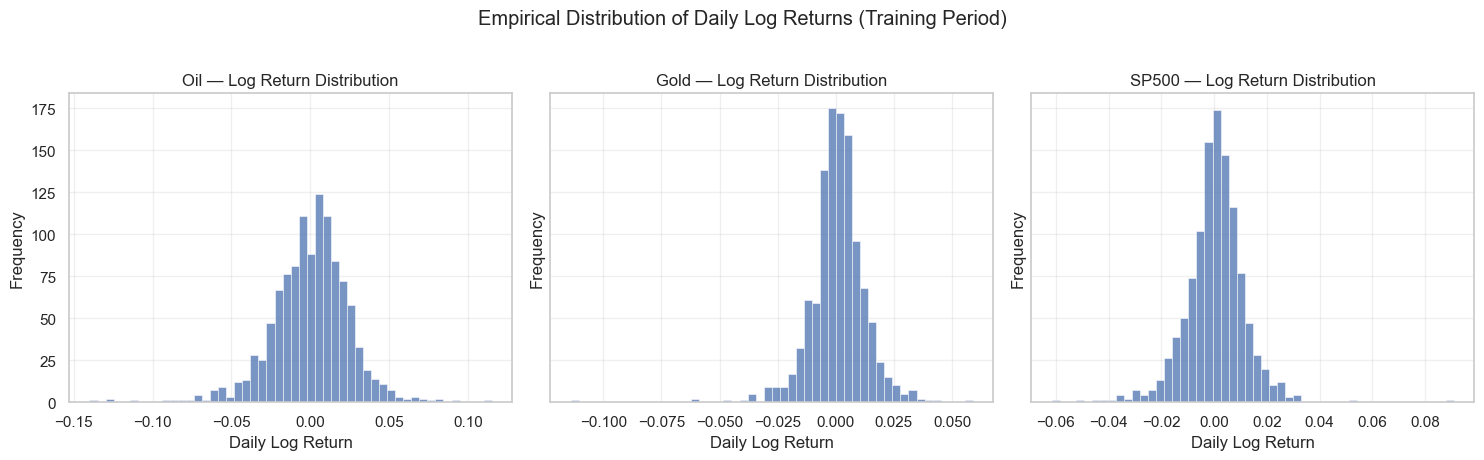

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4.5), sharey=True)

for ax, asset in zip(axes, returns.columns):
    series = returns[asset].dropna()
    ax.hist(series, bins=50, edgecolor="white", linewidth=0.5, alpha=0.75)
    ax.set_title(f"{asset} — Log Return Distribution")
    ax.set_xlabel("Daily Log Return")
    ax.set_ylabel("Frequency")
    ax.grid(True, alpha=0.3)

plt.suptitle("Empirical Distribution of Daily Log Returns (Training Period)", y=1.02)
plt.tight_layout()
plt.show()

## 6. Descriptive Statistics

The table below summarizes the key descriptive statistics for the training log returns of each asset:
- **Mean**: Average daily return
- **Std Dev**: Sample standard deviation (volatility)
- **Min / Max**: Extreme daily returns observed in the sample
- **Skewness**: Measure of asymmetry ($S = 0$ for normal distribution)
- **Excess Kurtosis**: Measure of tail thickness ($K_{\text{excess}} = K - 3 = 0$ for normal distribution)

In [7]:
# Compute summary statistics on training log returns
summary_stats = pd.DataFrame(index=returns.columns)
summary_stats["Mean"] = returns.mean()
summary_stats["Std Dev"] = returns.std()
summary_stats["Min"] = returns.min()
summary_stats["Max"] = returns.max()
summary_stats["Skewness"] = returns.skew()
summary_stats["Excess Kurtosis"] = returns.kurtosis()  # pandas computes Fisher's excess kurtosis (Normal = 0)

summary_stats.index.name = "Asset"
display(summary_stats.round(6))

,Mean,Std Dev,Min,Max,Skewness,Excess Kurtosis
Asset,,,,,,
Oil,0.000246,0.024450,-0.139985,0.115187,-0.523685,3.395149
Gold,0.000893,0.011767,-0.114060,0.058926,-1.037660,10.257572
SP500,0.000365,0.010973,-0.061609,0.090895,0.044753,6.326895


### 6.1 Interpretation of descriptive statistics

**Skewness:** Oil and Gold training returns show negative skew (left-heavy tails relative to the mean). S&P 500 skewness is approximately **+0.045**, i.e. **approximately symmetric** with a **very slight positive skew** — not materially asymmetric.

**Excess kurtosis:** All three series show positive excess kurtosis (fat tails versus a Gaussian), consistent with leptokurtic daily returns.


## 7. Outlier Analysis (Training Returns)

Extreme daily moves are identified using a **robust IQR rule** on each asset’s training log returns: values below $Q_1 - 1.5 \times \mathrm{IQR}$ or above $Q_3 + 1.5 \times \mathrm{IQR}$ are flagged as outliers. This is a descriptive screen only — **no observations are removed or winsorized** here (legitimate stress-day returns are retained for downstream modelling).


Flagged outliers (IQR rule, training only): 149


,Asset,Date,Log return,IQR lower,IQR upper
61,Gold,2021-11-22,-0.024770,-0.022166,0.024434
55,Gold,2022-03-09,-0.027336,-0.022166,0.024434
59,Gold,2022-05-02,-0.025483,-0.022166,0.024434
65,Gold,2022-06-13,-0.023576,-0.022166,0.024434
78,Gold,2022-11-04,0.027636,-0.022166,0.024434
...,...,...,...,...,...
122,SP500,2025-04-21,-0.023850,-0.021918,0.023094
133,SP500,2025-04-22,0.024807,-0.021918,0.023094
146,SP500,2025-05-12,0.032040,-0.021918,0.023094
115,SP500,2025-10-10,-0.027486,-0.021918,0.023094


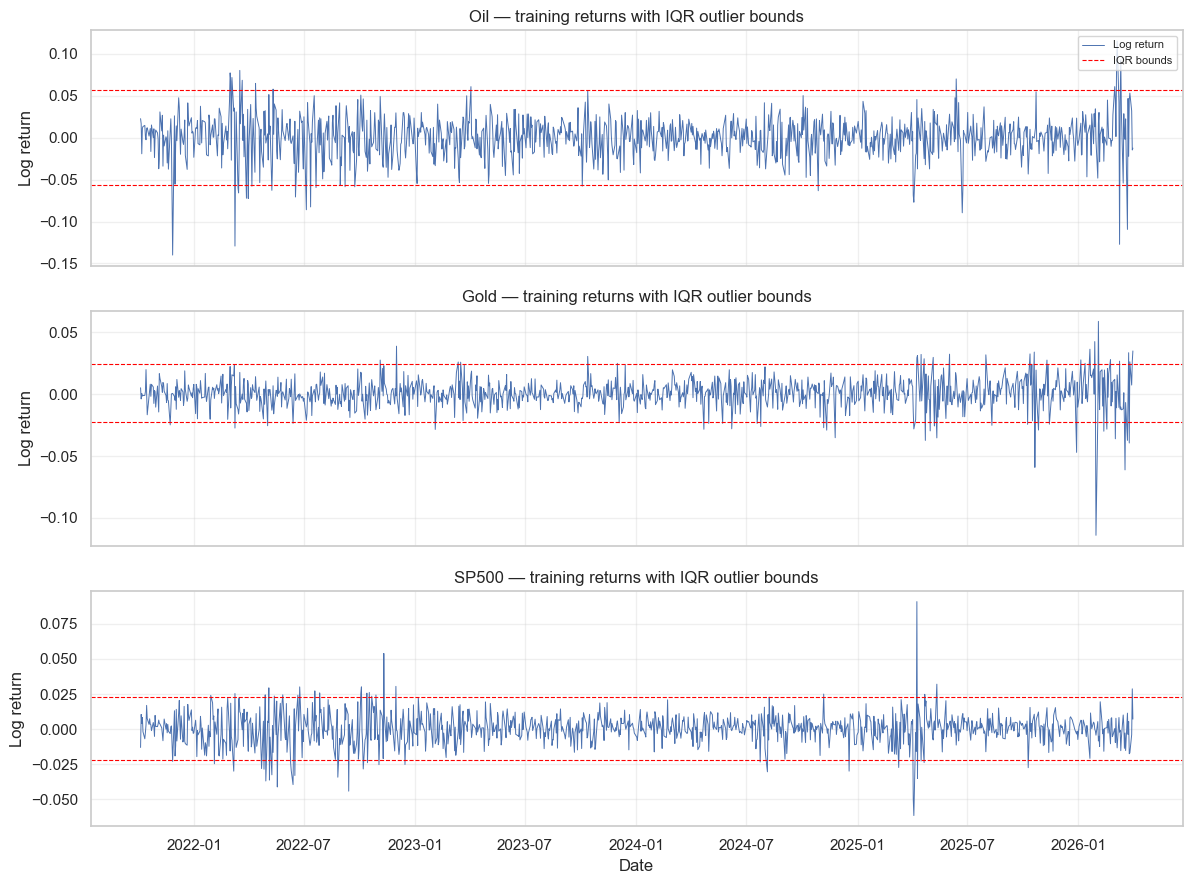

In [8]:

outlier_rows = []

for asset in returns.columns:
    series = returns[asset].dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    flagged = series[mask].sort_values()
    for dt, val in flagged.items():
        outlier_rows.append(
            {
                "Asset": asset,
                "Date": dt.date(),
                "Log return": val,
                "IQR lower": lower,
                "IQR upper": upper,
            }
        )

outlier_table = pd.DataFrame(outlier_rows)
print(f"Flagged outliers (IQR rule, training only): {len(outlier_table)}")
if len(outlier_table):
    display(outlier_table.sort_values(["Asset", "Date"]).round(6))
else:
    print("No outliers flagged under the IQR rule.")

# Visual: returns with IQR bounds
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 9), sharex=True)
for ax, asset in zip(axes, returns.columns):
    series = returns[asset].dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    ax.plot(series.index, series.values, linewidth=0.7, label="Log return")
    ax.axhline(lower, color="red", linestyle="--", linewidth=0.8, label="IQR bounds")
    ax.axhline(upper, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"{asset} — training returns with IQR outlier bounds")
    ax.set_ylabel("Log return")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Date")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


## 8. Correlation Analysis

The Pearson correlation matrix and heatmap quantify **linear** co-movements between the training log returns of Oil, Gold, and the S&P 500.

*Note: Correlation measures linear co-dependence and does not imply causation.*


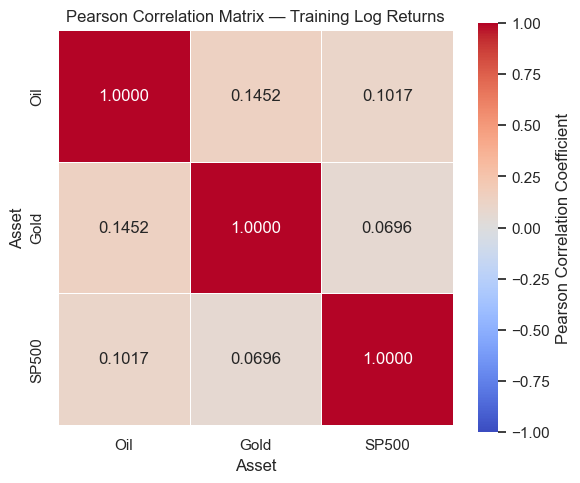

Correlation Matrix:


Asset,Oil,Gold,SP500
Asset,,,
Oil,1.0000,0.1452,0.1017
Gold,0.1452,1.0000,0.0696
SP500,0.1017,0.0696,1.0000


In [9]:
# Pearson correlation matrix of training log returns
corr_matrix = returns.corr(method="pearson")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
    ax=ax
)
ax.set_title("Pearson Correlation Matrix — Training Log Returns")
plt.tight_layout()
plt.show()

print("Correlation Matrix:")
display(corr_matrix.round(4))

### 8.1 Interpretation

Training pairwise Pearson correlations are **weak**: approximately **0.07–0.15** (Gold–SP500 ≈ 0.07, Oil–SP500 ≈ 0.10, Oil–Gold ≈ 0.15). These magnitudes indicate **weak linear relationships** in daily log returns over the training window. They do **not**, by themselves, establish meaningful diversification benefits — diversification also depends on volatilities, tail dependence, and investment horizons, which are not fully captured by linear correlation alone.


## 9. Rolling Volatility (20-Day Window)

Rolling volatility is estimated as the standard deviation of log returns over a trailing 20-observation window. This provides a non-parametric, time-varying measure of risk and makes volatility clustering visually apparent.

The calculation is performed in-memory on the **training returns** loaded in Section 1 (not on the full `rolling_volatility_20d.csv`, which covers the entire dataset including the test period). The first 19 observations produce `NaN` values, which are omitted from the plot automatically.


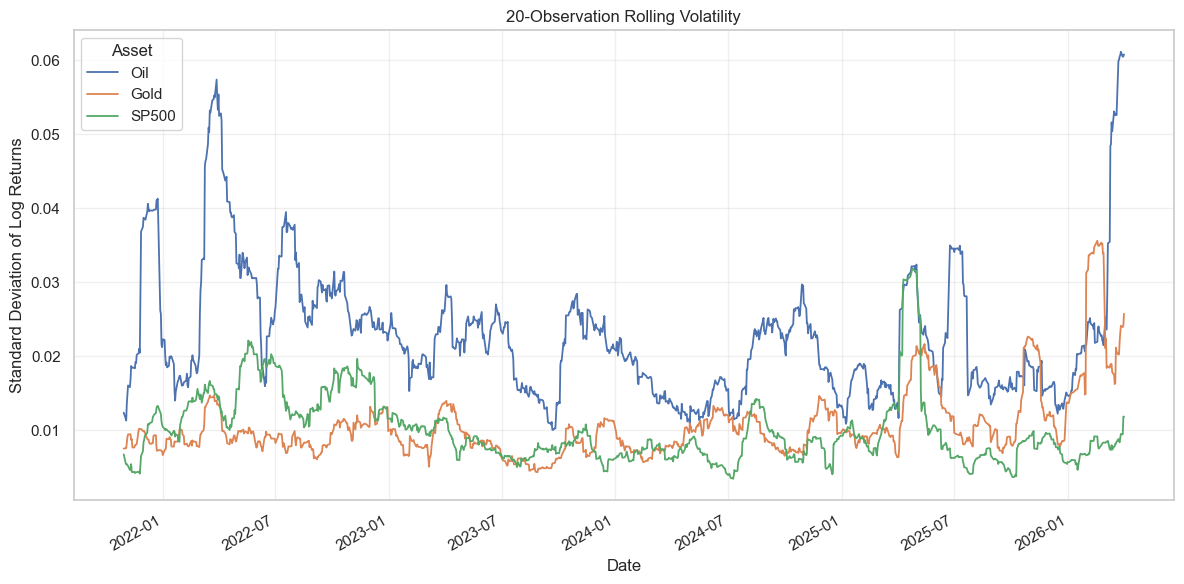

In [10]:

# Calculate the rolling standard deviation of returns.
rolling_volatility = returns.rolling(window=20).std()

fig, ax = plt.subplots(figsize=(12, 6))

rolling_volatility.plot(ax=ax, linewidth=1.3)

ax.set_title("20-Observation Rolling Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Standard Deviation of Log Returns")
ax.legend(title="Asset")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Seasonal Decomposition (STL, Training Prices)

STL decomposition separates each **training price** series into trend, seasonal, and residual components. A **period of 5** trading days is used as a minimal weekly seasonal template.

**Limitations:** Daily financial prices are not generated by a stable seasonal process; the seasonal component is often near zero and the trend dominates. Results are presented for assignment completeness and should be read as exploratory, not as evidence of true calendar seasonality.


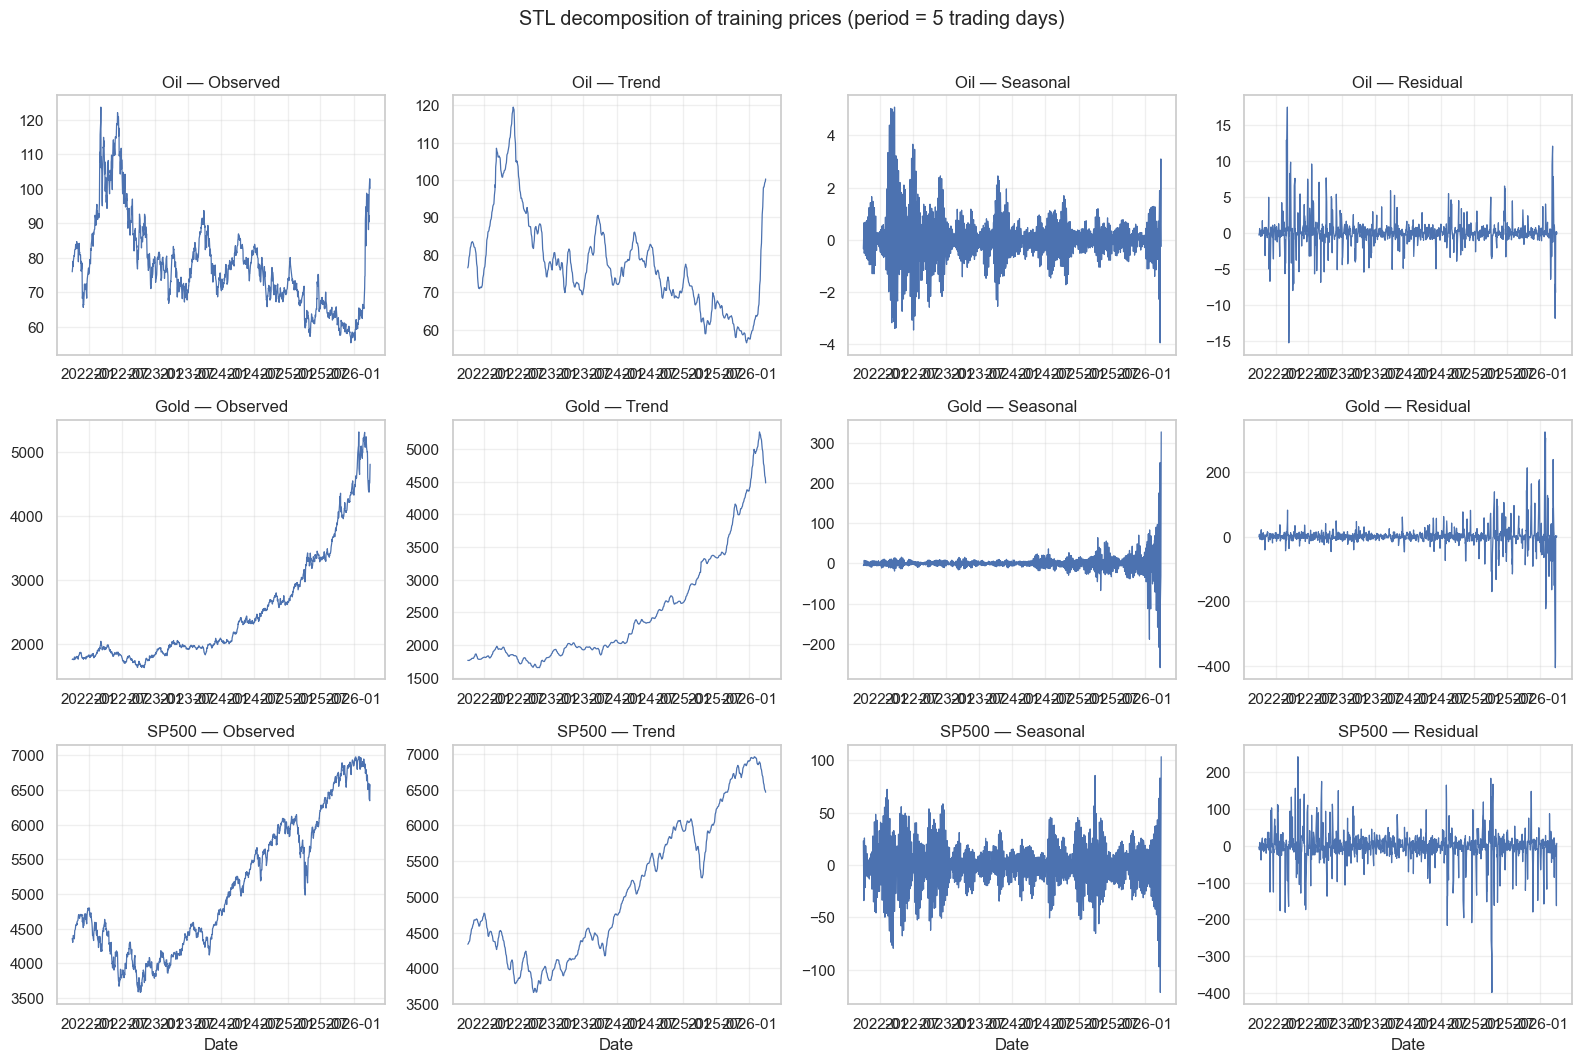

In [11]:

from statsmodels.tsa.seasonal import STL

STL_PERIOD = 5  # trading-day week template

fig, axes = plt.subplots(nrows=len(prices.columns), ncols=4, figsize=(16, 3.5 * len(prices.columns)))
if len(prices.columns) == 1:
    axes = np.array([axes])

for row, asset in enumerate(prices.columns):
    series = prices[asset].dropna()
    stl = STL(series, period=STL_PERIOD, robust=True)
    result = stl.fit()
    components = {
        "Observed": result.observed,
        "Trend": result.trend,
        "Seasonal": result.seasonal,
        "Residual": result.resid,
    }
    for col, (name, comp) in enumerate(components.items()):
        ax = axes[row, col]
        ax.plot(comp.index, comp.values, linewidth=0.9)
        ax.set_title(f"{asset} — {name}")
        ax.grid(True, alpha=0.3)
        if row == len(prices.columns) - 1:
            ax.set_xlabel("Date")

plt.suptitle("STL decomposition of training prices (period = 5 trading days)", y=1.01)
plt.tight_layout()
plt.show()


## 11. Stationarity Analysis

Stationarity tests are used to determine whether a time series has constant mean, variance, and autocovariance over time:

- **Augmented Dickey-Fuller (ADF) Test**:
  - $H_0$: Unit root present (non-stationary)
  - $H_1$: Series is stationary
- **KPSS Test**:
  - $H_0$: Series is level stationary
  - $H_1$: Unit root present (non-stationary)

A series is confirmed stationary if ADF rejects $H_0$ ($p < 0.05$) AND KPSS fails to reject $H_0$ ($p \ge 0.05$).


In [12]:

import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

def test_stationarity(series, series_name):
    series = pd.to_numeric(series, errors="coerce")
    series = series.replace([np.inf, -np.inf], np.nan).dropna()

    adf = adfuller(series, autolag="AIC")
    kpss_result = kpss(series, regression="c", nlags="auto")

    return {
        "Series": series_name,
        "Observations": len(series),
        "ADF Statistic": adf[0],
        "ADF p-value": adf[1],
        "ADF 5% Critical Value": adf[4]["5%"],
        "KPSS Statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
        "KPSS 5% Critical Value": kpss_result[3]["5%"],
    }

results = []

for col in prices.columns:
    results.append(
        test_stationarity(prices[col], f"{col} Price (Train)")
    )

for col in returns.columns:
    results.append(
        test_stationarity(returns[col], f"{col} Log Return (Train)")
    )

stationarity_results = pd.DataFrame(results)

# Validate the output structure before displaying it
expected_columns = [
    "Series",
    "Observations",
    "ADF Statistic",
    "ADF p-value",
    "ADF 5% Critical Value",
    "KPSS Statistic",
    "KPSS p-value",
    "KPSS 5% Critical Value",
]

stationarity_results = stationarity_results[expected_columns]

display(stationarity_results.round(5))


C:\Users\kenza\AppData\Local\Temp\ipykernel_22004\1112057115.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series, autolag="AIC")
C:\Users\kenza\AppData\Local\Temp\ipykernel_22004\1112057115.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression="c", nlags="auto")
C:\Users\kenza\AppData\Local\Temp\ipykernel_22004\1112057115.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or

,Series,Observations,ADF Statistic,ADF p-value,ADF 5% Critical Value,KPSS Statistic,KPSS p-value,KPSS 5% Critical Value
0,Oil Price (Train),1129,-1.88602,0.33866,-2.86412,2.77646,0.01000,0.463
1,Gold Price (Train),1129,2.19005,0.99887,-2.86414,4.32535,0.01000,0.463
2,SP500 Price (Train),1129,-0.22523,0.93545,-2.86411,4.76607,0.01000,0.463
3,Oil Log Return (Train),1128,-15.57229,0.00000,-2.86412,0.09792,0.10000,0.463
4,Gold Log Return (Train),1128,-34.84784,0.00000,-2.86411,0.38862,0.08206,0.463
5,SP500 Log Return (Train),1128,-20.73014,0.00000,-2.86411,0.13308,0.10000,0.463


## 12. ACF and PACF Analysis

The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) measure the linear dependence of a series on its own past values. They are used to identify candidate ARMA orders:

- **ACF** cuts off after lag *q* → MA(*q*) component
- **PACF** cuts off after lag *p* → AR(*p*) component

Both functions are applied to the **training log returns only** (not the test set) to avoid any look-ahead bias in model identification.


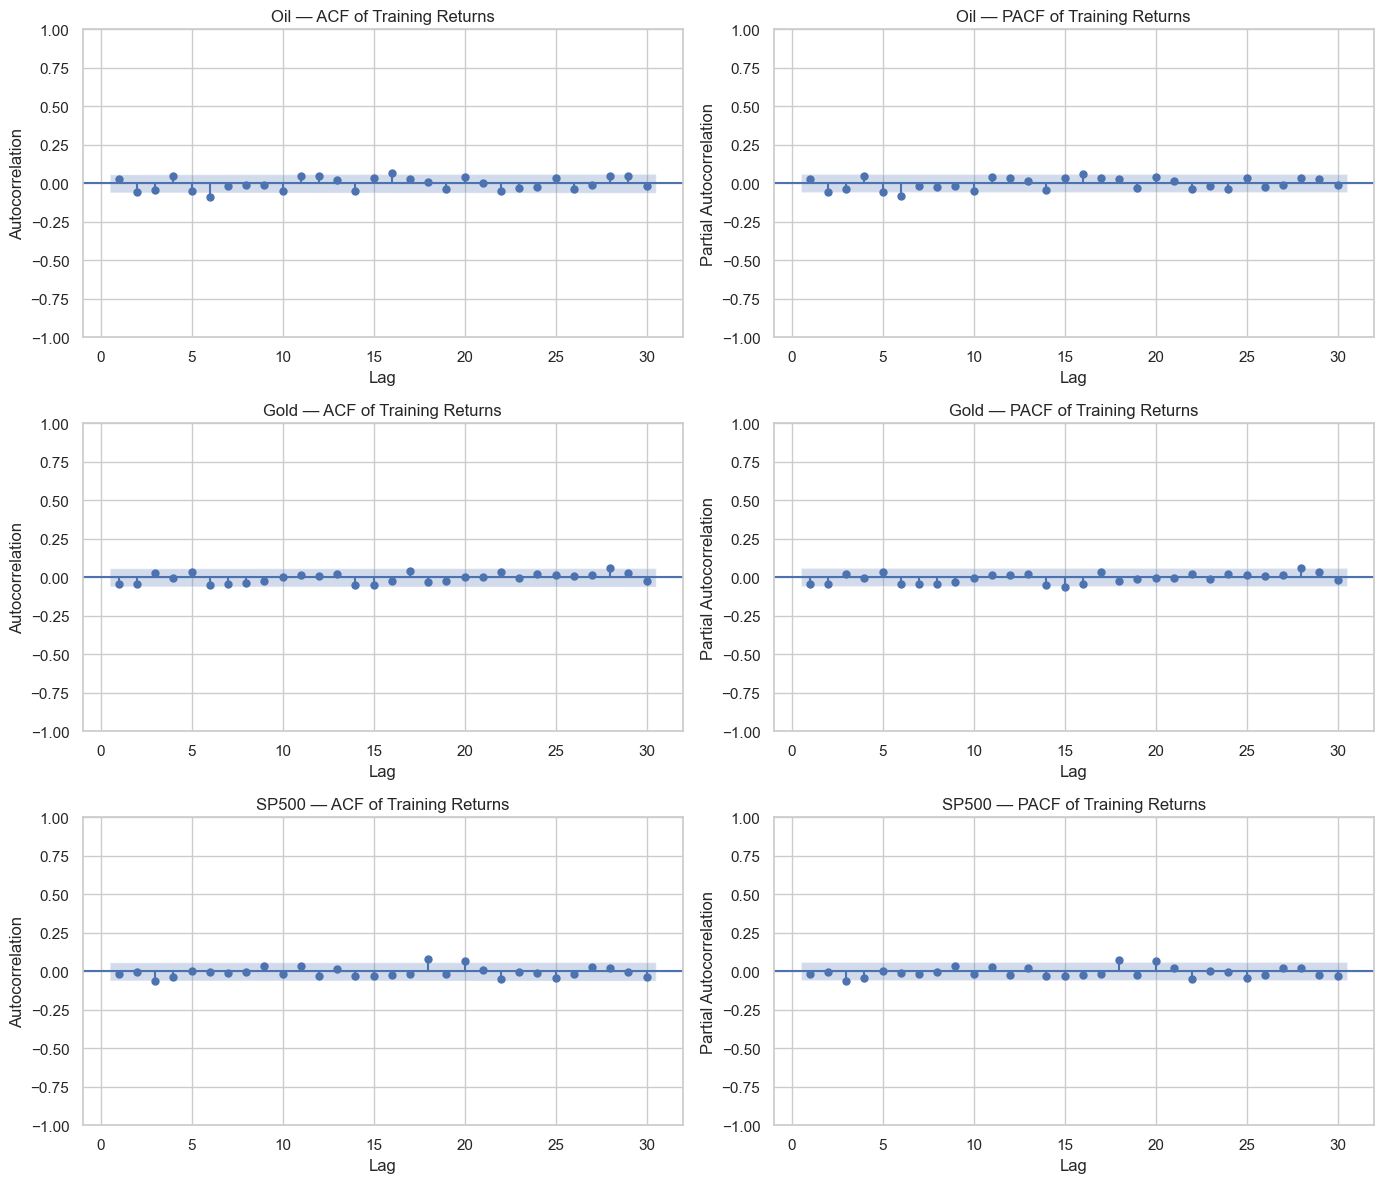

In [13]:

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Use training returns only
returns = returns.sort_index()

assets = returns.columns.tolist()

fig, axes = plt.subplots(
    nrows=len(assets),
    ncols=2,
    figsize=(14, 4 * len(assets))
)

for i, asset in enumerate(assets):
    series = returns[asset].dropna()

    # ACF
    plot_acf(
        series,
        lags=30,
        ax=axes[i, 0],
        zero=False
    )
    axes[i, 0].set_title(f"{asset} — ACF of Training Returns")
    axes[i, 0].set_xlabel("Lag")
    axes[i, 0].set_ylabel("Autocorrelation")

    # PACF
    plot_pacf(
        series,
        lags=30,
        ax=axes[i, 1],
        method="ywm",
        zero=False
    )
    axes[i, 1].set_title(f"{asset} — PACF of Training Returns")
    axes[i, 1].set_xlabel("Lag")
    axes[i, 1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

## 13. Ljung–Box Test (Training Returns)

The Ljung–Box test evaluates whether autocorrelations up to lag *h* are jointly zero. It complements the ACF plots in Section 12. Here we use **lags 1–10** (daily horizon) on **training log returns** (level series, not squared returns).

| Hypothesis | Statement |
|-----------|----------|
| **H₀** | No autocorrelation up to lag *h* |
| **H₁** | At least one autocorrelation is non-zero |

A small p-value suggests serial dependence; for returns, marginal significance at a few lags can occur without strong predictability.

**Training-sample reading:** Gold and SP500 do not reject H₀ at the 5% level over lags 1–10. **Oil rejects H₀ at lag 6** (Ljung–Box p ≈ 0.002), even though the corresponding ACF magnitudes remain small (e.g. lag-6 ACF ≈ −0.09). Treat this as statistically detectable but economically weak serial dependence.


In [14]:

from statsmodels.stats.diagnostic import acorr_ljungbox

LJUNG_BOX_LAGS = list(range(1, 11))

ljung_rows = []
for asset in returns.columns:
    series = returns[asset].dropna()
    lb = acorr_ljungbox(series, lags=LJUNG_BOX_LAGS, return_df=True)
    min_p = lb["lb_pvalue"].min()
    ljung_rows.append(
        {
            "Asset": asset,
            "Min p-value (lags 1-10)": min_p,
            "Conclusion (5%)": (
                "Reject H0 at at least one lag"
                if min_p < 0.05
                else "No rejection of H0 at 5%"
            ),
        }
    )
    print(f"\n{asset} — Ljung-Box p-values (lags 1-10):")
    display(lb.round(6))

ljung_summary = pd.DataFrame(ljung_rows)
display(ljung_summary.round(6))



Oil — Ljung-Box p-values (lags 1-10):


,lb_stat,lb_pvalue
1,0.764331,0.381977
2,4.176054,0.123931
3,6.181414,0.103110
4,8.995998,0.061200
5,12.060909,0.033963
6,21.106982,0.001755
7,21.522196,0.003069
8,21.605905,0.005701
9,21.789875,0.009569
10,24.712807,0.005917



Gold — Ljung-Box p-values (lags 1-10):


,lb_stat,lb_pvalue
1,1.954790,0.162072
2,3.800192,0.149554
3,4.707175,0.194539
4,4.710823,0.318276
5,5.999905,0.306228
6,8.484512,0.204711
7,10.353338,0.169419
8,11.858865,0.157613
9,12.554623,0.183816
10,12.557715,0.249462



SP500 — Ljung-Box p-values (lags 1-10):


,lb_stat,lb_pvalue
1,0.310776,0.577205
2,0.319159,0.852502
3,5.073090,0.166523
4,6.795317,0.147108
5,6.810521,0.235118
6,6.840785,0.335823
7,6.965783,0.432451
8,6.991848,0.537512
9,8.547820,0.480015
10,8.789304,0.552209


,Asset,Min p-value (lags 1-10),Conclusion (5%)
0,Oil,0.001755,Reject H0 at at least one lag
1,Gold,0.149554,No rejection of H0 at 5%
2,SP500,0.147108,No rejection of H0 at 5%


## 14. ACF of Squared and Absolute Returns

Significant autocorrelation in **squared** or **absolute** returns is a standard diagnostic for volatility clustering and ARCH-type effects. If the return series itself has little serial correlation while its squared or absolute values do, this suggests that the conditional variance is time-varying — the key motivation for GARCH models.

The plots below apply the ACF to squared returns ($r_t^2$) and absolute returns ($|r_t|$) computed from the training set.


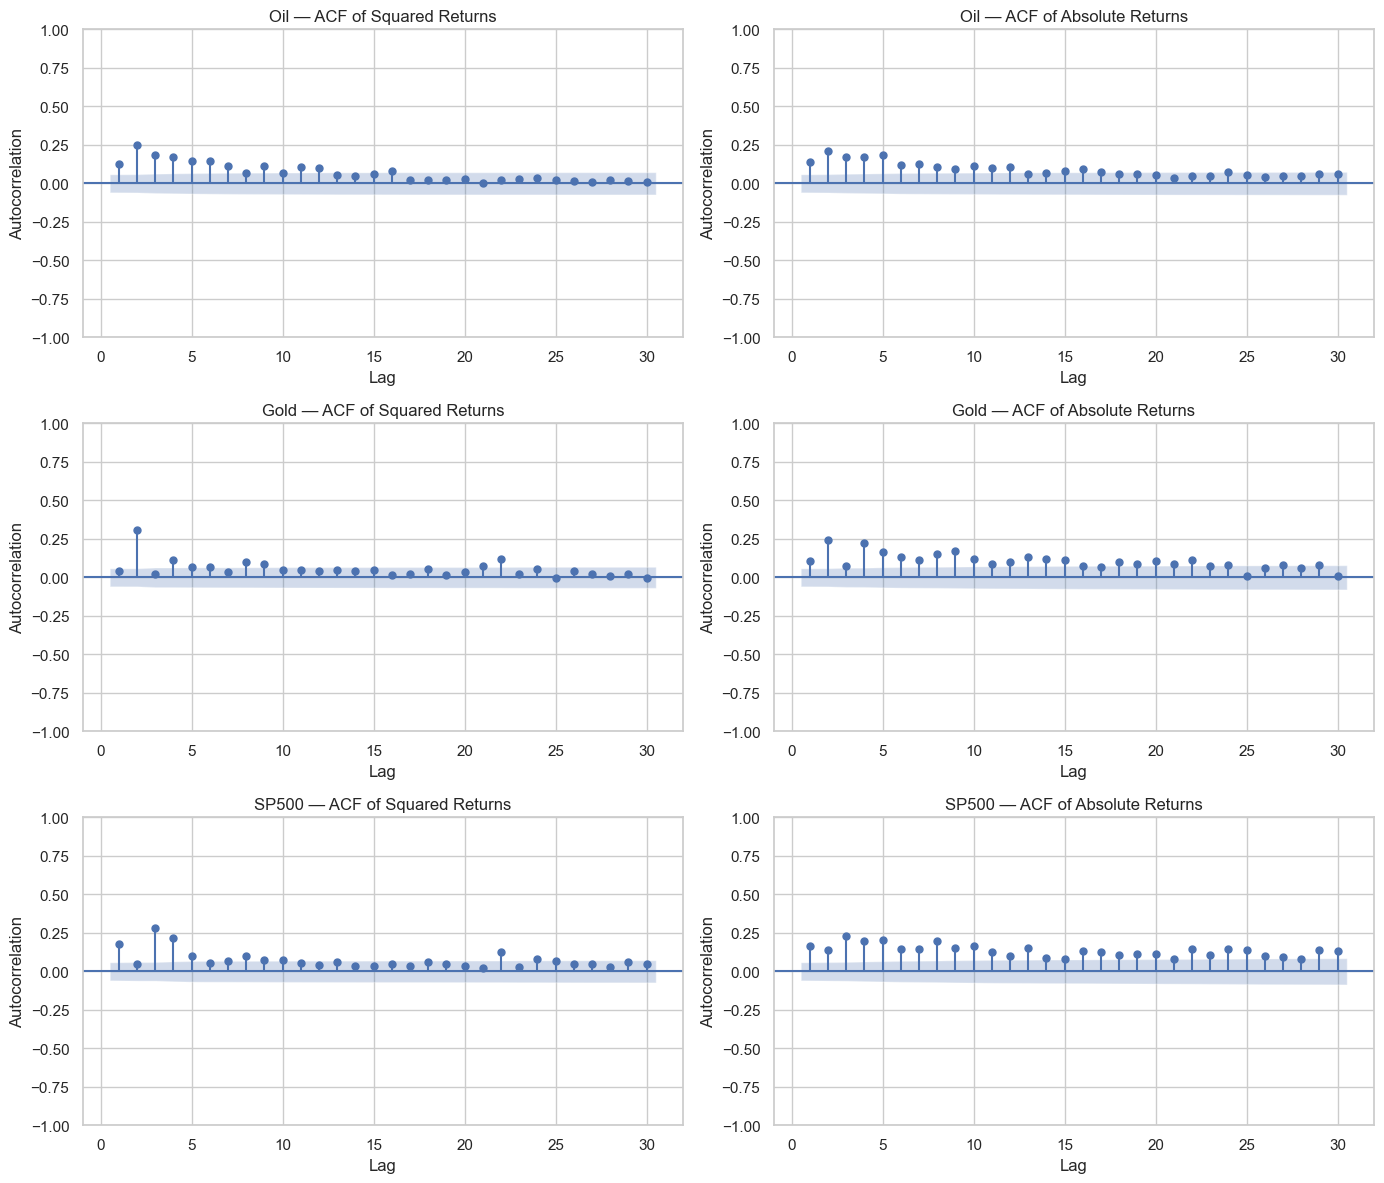

In [15]:

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
import numpy as np

# Use training log returns only
returns = returns.sort_index()

assets = returns.columns.tolist()

fig, axes = plt.subplots(
    nrows=len(assets),
    ncols=2,
    figsize=(14, 4 * len(assets))
)

for i, asset in enumerate(assets):
    series = returns[asset].dropna()

    # ACF of squared returns
    squared_returns = series ** 2
    plot_acf(
        squared_returns,
        lags=30,
        ax=axes[i, 0],
        zero=False
    )
    axes[i, 0].set_title(f"{asset} — ACF of Squared Returns")
    axes[i, 0].set_xlabel("Lag")
    axes[i, 0].set_ylabel("Autocorrelation")

    # ACF of absolute returns
    absolute_returns = series.abs()
    plot_acf(
        absolute_returns,
        lags=30,
        ax=axes[i, 1],
        zero=False
    )
    axes[i, 1].set_title(f"{asset} — ACF of Absolute Returns")
    axes[i, 1].set_xlabel("Lag")
    axes[i, 1].set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

## 15. ARCH-LM Test for Conditional Heteroskedasticity

Engle's ARCH-LM test formally tests whether the residual variance is constant over time. It is applied here to **demeaned training log returns** using 10 lags.

| Hypothesis | Statement |
|-----------|----------|
| **H₀** | No ARCH effects (conditional variance is constant) |
| **H₁** | ARCH effects present (conditional variance depends on past shocks) |

The test statistic follows a χ² distribution under H₀. A p-value below 0.05 leads to rejection.


In [16]:

import pandas as pd
from statsmodels.stats.diagnostic import het_arch

# Use training returns only
returns = returns.sort_index()

arch_results = []

for asset in returns.columns:
    series = returns[asset].dropna()

    # Mean-model residuals: demeaned returns
    residuals = series - series.mean()

    # Engle's ARCH-LM test
    lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
        residuals,
        nlags=10
    )

    arch_results.append({
        "Asset": asset,
        "Observations": len(residuals),
        "ARCH-LM Statistic": lm_stat,
        "LM p-value": lm_pvalue,
        "F Statistic": f_stat,
        "F p-value": f_pvalue,
        "Conclusion (5%)": (
            "ARCH effects detected"
            if lm_pvalue < 0.05
            else "Insufficient evidence of ARCH effects"
        )
    })

arch_results = pd.DataFrame(arch_results)

display(arch_results.round(5))

C:\Users\kenza\AppData\Roaming\Python\Python314\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Asset,Observations,ARCH-LM Statistic,LM p-value,F Statistic,F p-value,Conclusion (5%)
0,Oil,1128,119.07673,0.0,13.19600,0.0,ARCH effects detected
1,Gold,1128,114.77792,0.0,12.66511,0.0,ARCH effects detected
2,SP500,1128,151.49999,0.0,17.35235,0.0,ARCH effects detected


## 16. Key Observations and Conclusions

### 16.1 Price and Return Characteristics
- **Original & Normalized Prices:** All three assets exhibit non-stationary level behaviour over the 2021–2026 training window, with pronounced trend and regime shifts.
- **Return Distributions & Fat Tails:** All three return series show positive excess kurtosis (leptokurtosis). Oil and Gold show negative skew; **S&P 500 skewness is ≈ +0.045 (approximately symmetric with very slight positive skew)**.
- **Cross-Asset Correlations:** Pairwise Pearson correlations on training returns are **weak (≈ 0.07–0.15)**. They indicate **weak linear co-movement** only; **no strong diversification claim** is made from correlation alone.

### 16.2 Outliers
The IQR-based screen (Section 7) lists extreme training daily returns by date. These are retained in the sample for modelling.

### 16.3 Decomposition
STL on training prices (Section 10) is dominated by the trend; seasonal structure is weak — consistent with limitations of seasonal models on daily financial prices.

### 16.4 Stationarity
The stationarity tests (Section 11) confirm that **price levels are integrated of order 1** ($I(1)$): the ADF fails to reject the unit root and the KPSS rejects stationarity for all three assets. **Log returns are stationary** ($I(0)$): the ADF strongly rejects the unit root ($p < 0.001$ for all series) and the KPSS fails to reject stationarity.

### 16.5 Serial Correlation in Returns
The ACF and PACF of log returns (Section 12) show no economically large autocorrelation at short lags. The Ljung–Box test (Section 13) on lags 1–10 does not reject H₀ for Gold or SP500 at 5%; **Oil rejects at lag 6 (p ≈ 0.002)** despite small ACF magnitudes—interpret jointly with effect size and the ACF plots.

### 16.6 Volatility Clustering and ARCH Effects
- **ACF of Squared/Absolute Returns:** Persistent autocorrelation in squared and absolute returns supports volatility clustering.
- **Engle's ARCH-LM Test:** For all three assets, the test produced $p$-values below 0.001 ($p < 0.001$), rejecting homoskedasticity.
- **Conclusion for Modeling:** Conditional heteroskedasticity is present in the training sample, motivating GARCH-type models in later work (outside this notebook).
